# <u> NOTEBOOK PERMETTANT DE REPONDRE AUX DEMANDES D'ANNABELLE </U>

### <u> Import des librairies utiles pour ce projet </u>

In [1]:
# Importation des librairies

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
# import plotly.subplots as sp
# import plotly.graph_objects as go
# import statsmodels.api as sm

In [2]:
# Palette de couleurs

px.colors.qualitative.LibrairieContrast = [
    "#2f3a4a",  
    "#7f5083",  
    "#e95c6d",  
    "#ffa600",  
    "#4c9f70", 
    "#3b7dd8", 
    "#b95383"   
]

px.colors.qualitative.Librairie3 = [
    "#e95c6d",
    "#2f3a4a",
    "#ffa600",
]

palette = {
    "0": "#e95c6d",
    "1": "#2f3a4a",
    "2": "#ffa600"
}

palette = list(palette.values())

### <u> Chargement du dataset selon les csv remis lors de la mission </u>

In [4]:
df_lapage=pd.read_csv(r'C:\Users\frnar\OneDrive\Desktop\Projets OC 2.0\Projet 9\df_lapage.csv',sep=';', encoding='utf-8', low_memory=False)

In [6]:
print("Les données minimales par colonne sont les suivantes :")
print(df_lapage.min(numeric_only=True))

print("\n" + "-" * 60)

print("Les données maximales par colonne sont les suivantes :")
print(df_lapage.max(numeric_only=True))

print("\n" + "-" * 60)

print("Le type de chaque colonne est :")
print(df_lapage.dtypes)

Les données minimales par colonne sont les suivantes :
price       0.62
categ       0.00
birth    1929.00
dtype: float64

------------------------------------------------------------
Les données maximales par colonne sont les suivantes :
price     300.0
categ       2.0
birth    2004.0
dtype: float64

------------------------------------------------------------
Le type de chaque colonne est :
id_prod        object
date           object
session_id     object
client_id      object
price         float64
categ         float64
sex            object
birth         float64
dtype: object


In [7]:
# Conversion de la colonne date en datetime
df_lapage['date'] = pd.to_datetime(df_lapage['date'])

### IDENTIFICATION DES B2B ET B2C DES LE DEBUT DES ANALYSES

In [8]:
# Nous identifions 4 clients ayant généré plusieurs centaines de milliers d'euros de CA
ca_par_client = df_lapage.groupby(['client_id'])['price'].sum().reset_index().sort_values('price', ascending=False)
ca_par_client.head(10)
# clients = ['c_1609','c_4958','c_6714','c_3454']

,client_id,price
677,c_1609,326039.89
4388,c_4958,290227.03
6337,c_6714,153918.60
2724,c_3454,114110.57
634,c_1570,5285.82
2513,c_3263,5276.87
1268,c_2140,5260.18
2108,c_2899,5214.05
7006,c_7319,5155.77
7715,c_7959,5135.75


In [9]:
# Création d'une colonne dans le df, précisant s'il s'agit d'un client B2B ou B2C selon le tri ci-dessus
clients = ['c_1609','c_4958','c_6714','c_3454']
df_lapage['type_client']=df_lapage['client_id'].apply(lambda x: 'B to B' if x in clients else 'B to C')
df_lapage.head(20)

# Création d'un df b2b 
df_b2b = df_lapage[df_lapage['client_id'].isin(clients)]

# Mise à jour du df principal excluant ces 4 clients
df_b2c = df_lapage[df_lapage['type_client'] == 'B to C'].copy()
df_b2c

,id_prod,date,session_id,client_id,price,categ,sex,birth,type_client
0,0_1259,2021-03-01,s_1,c_329,11.99,0.0,f,1967.0,B to C
1,0_1390,2021-03-01,s_2,c_664,19.37,0.0,m,1960.0,B to C
2,0_1352,2021-03-01,s_3,c_580,4.50,0.0,m,1988.0,B to C
3,0_1458,2021-03-01,s_4,c_7912,6.55,0.0,f,1989.0,B to C
4,0_1358,2021-03-01,s_5,c_2033,16.49,0.0,f,1956.0,B to C
...,...,...,...,...,...,...,...,...,...
1048570,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,B to C
1048571,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,B to C
1048572,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,B to C
1048573,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,B to C


### DONNEES GLOBALES - INSIGHTS

In [10]:
ca=df_lapage['price'].sum()
print(ca)

12027663.100000003


In [11]:
# EXEMPLAIRES VENDUS TOTAL
total_exemplaires=df_lapage['session_id'].value_counts().sum()
print(total_exemplaires)

687534


#### Répartition par produits

In [12]:
#  NOMBRE DE PRODUITS DISTINCTS
total_produits = df_lapage['id_prod'].nunique()
print(total_produits)

3265


In [13]:
#  NOMBRE DE PRODUITS DISTINCTS PAR CATEGORIE
total_produits = df_lapage.groupby('categ')['id_prod'].nunique().reset_index()
print(total_produits)

   categ  id_prod
0    0.0     2292
1    1.0      737
2    2.0      236


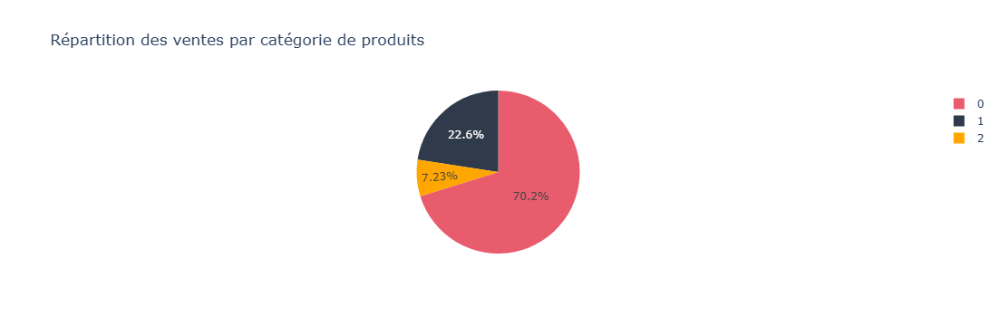

In [14]:
figure_categ=px.pie(
    total_produits,
    names='categ',
    values='id_prod', 
    title='Répartition des ventes par catégorie de produits', 
    color_discrete_sequence=palette
    )
figure_categ.show()

In [15]:
# NOMBRE TOTAL DE CLIENTS DISTINCTS
total_clients = df_lapage['client_id'].nunique()
print(total_clients)

8600


## <u> 1. Le chiffre d'affaires </u>

#### Chiffre d’affaires par catégorie de clients

In [16]:
#  CA mensuel moyen
ca_mensuel = df_lapage.groupby(pd.Grouper(key='date', freq='W'))['price'].sum().to_frame().reset_index()
ca_mensuel.head(10)


,date,price
0,2021-03-07,110463.28
1,2021-03-14,105693.24
2,2021-03-21,112059.08
3,2021-03-28,109441.07
4,2021-04-04,107895.66
5,2021-04-11,112151.56
6,2021-04-18,108561.21
7,2021-04-25,112798.95
8,2021-05-02,110675.79
9,2021-05-09,115403.87


In [17]:
# Création de la colonne indiquant une moyenne glissante sur une semaine
ca_mensuel['Moyenne glissante (mois)']=ca_mensuel['price'].rolling(window=4).mean().round(2)
ca_mensuel

,date,price,Moyenne glissante (mois)
0,2021-03-07,110463.28,NaN
1,2021-03-14,105693.24,NaN
2,2021-03-21,112059.08,NaN
3,2021-03-28,109441.07,109414.17
4,2021-04-04,107895.66,108772.26
...,...,...,...
100,2023-02-05,113486.13,115826.18
101,2023-02-12,112528.15,114423.31
102,2023-02-19,114121.61,114878.94
103,2023-02-26,112245.15,113095.26


In [18]:
# Création de la colonne indiquant une moyenne glissante sur une semaine
ca_mensuel['Moyenne glissante (trim)']=ca_mensuel['price'].rolling(window=12).mean().round(2)
ca_mensuel = ca_mensuel.rename(columns={'price': 'CA hebdomadaire moyen'})
ca_mensuel

,date,CA hebdomadaire moyen,Moyenne glissante (mois),Moyenne glissante (trim)
0,2021-03-07,110463.28,NaN,NaN
1,2021-03-14,105693.24,NaN,NaN
2,2021-03-21,112059.08,NaN,NaN
3,2021-03-28,109441.07,109414.17,NaN
4,2021-04-04,107895.66,108772.26,NaN
...,...,...,...,...
100,2023-02-05,113486.13,115826.18,115635.42
101,2023-02-12,112528.15,114423.31,115727.49
102,2023-02-19,114121.61,114878.94,115710.42
103,2023-02-26,112245.15,113095.26,115190.10


C:\Users\frnar\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



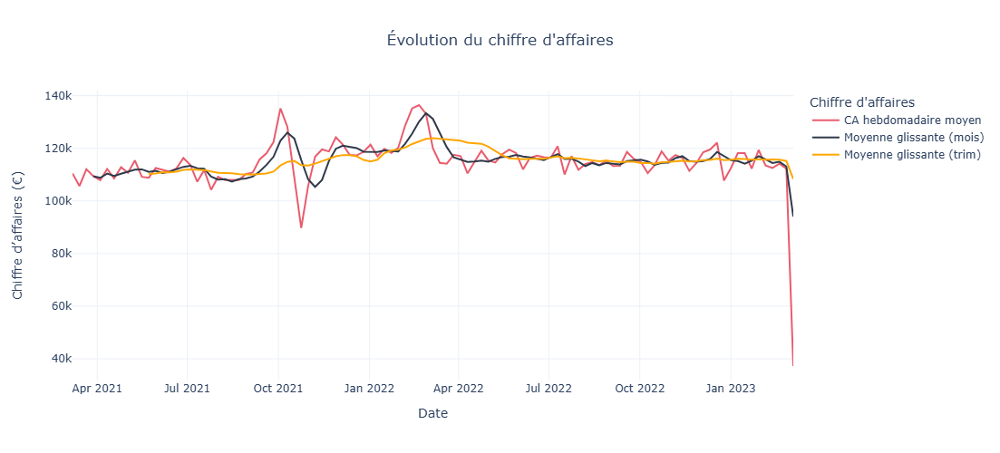

In [21]:
figure = px.line(
    ca_mensuel, 
    x='date', 
    y=['CA hebdomadaire moyen', 'Moyenne glissante (mois)','Moyenne glissante (trim)'], 
    color_discrete_sequence=palette,
    markers=False,
    title='Évolution du chiffre d\'affaires',
    labels={
        'date': 'Date',
        'value': 'Chiffre d’affaires (€)',
        'variable': 'Chiffre d\'affaires'
    }
)

figure.update_layout(
    title={
        'text': "Évolution du chiffre d'affaires",
        'x': 0.5,          
        'xanchor': 'center'},
    template='plotly_white',
    hovermode='x unified',
    width=1050,
    height=500
)

figure.update_traces(
    hovertemplate='%{y:.0f}€'
)

figure.show()

In [22]:
# 1er en termes de CA
top1=df_lapage[df_lapage['id_prod'] == '2_166']
top1

,id_prod,date,session_id,client_id,price,categ,sex,birth,type_client
2134,2_166,2021-03-03,s_1070,c_7472,230.04,2.0,f,2004.0,B to C
3824,2_166,2021-03-05,s_1894,c_6870,230.04,2.0,m,1992.0,B to C
7013,2_166,2021-03-08,s_3482,c_6978,230.04,2.0,m,1996.0,B to C
18460,2_166,2021-03-20,s_9158,c_3367,230.04,2.0,f,1956.0,B to C
23489,2_166,2021-03-26,s_11639,c_2737,230.04,2.0,m,1998.0,B to C
...,...,...,...,...,...,...,...,...,...
676925,2_166,2023-02-17,s_342972,c_269,230.04,2.0,f,1996.0,B to C
679916,2_166,2023-02-20,s_344543,c_3367,230.04,2.0,f,1956.0,B to C
680080,2_166,2023-02-21,s_344633,c_2329,230.04,2.0,f,1996.0,B to C
682155,2_166,2023-02-23,s_345672,c_563,230.04,2.0,f,2002.0,B to C


#### Chiffre d’affaires par catégorie + évolution dans le temps

In [23]:
# Création d'un df contenant les données agregées par mois
df_lapage_mois = df_lapage.groupby([pd.Grouper(key='date', freq='MS'), 'categ'])['price'].sum().reset_index()
df_lapage_mois['date AAAA-MM'] = df_lapage_mois['date'].dt.strftime('%Y-%m')

In [24]:
# Vérification des catégories uniques présentes dans la colonne categ
categories =df_lapage_mois.categ.unique()
print('Les catégories uniques du df sont les suivantes :', categories)

Les catégories uniques du df sont les suivantes : [0. 1. 2.]


In [25]:
# Affichage du chiffre d'affaire par catégorie sur l'intégralité de la période du dataset
for categ in df_lapage_mois.categ.unique():
    ca = df_lapage_mois[df_lapage_mois['categ'] == categ]['price'].sum()
    print (f'Le chiffre d\'affaire total de la catégorie {categ} est de {ca:,.0f} euros'.replace(',',' '))

Le chiffre d'affaire total de la catégorie 0.0 est de 4 419 731 euros
Le chiffre d'affaire total de la catégorie 1.0 est de 4 827 657 euros
Le chiffre d'affaire total de la catégorie 2.0 est de 2 780 275 euros


C:\Users\frnar\anaconda3\Lib\site-packages\plotly\express\_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

C:\Users\frnar\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



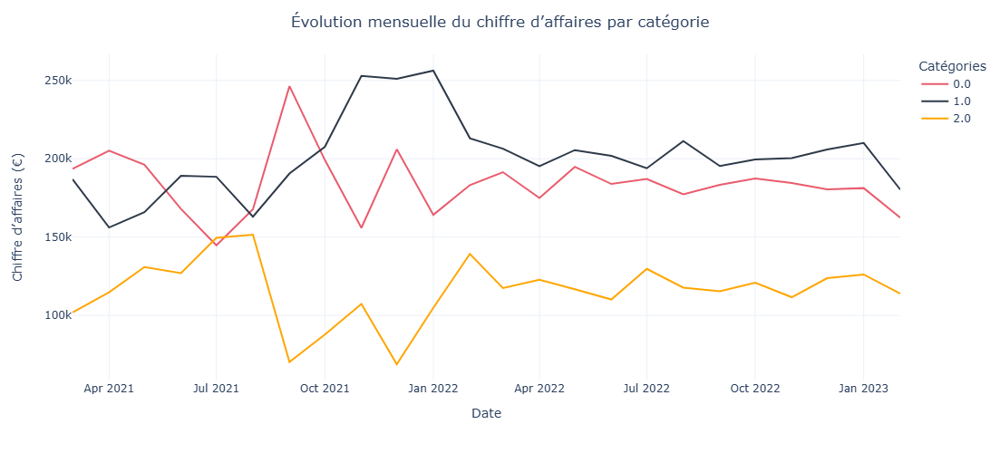

In [26]:
figure2 = px.line(
    df_lapage_mois, 
    x='date', 
    y='price', 
    color='categ',
    color_discrete_sequence=palette,
    markers=False,
    
    labels={
        'date': 'Date',
        'price': 'Chiffre d’affaires (€)',
        'categ': 'Catégories'
    }
)

figure2.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=1050,
    height=500,
    title={
        'text': 'Évolution mensuelle du chiffre d’affaires par catégorie',
        'x': 0.5,          
        'xanchor': 'center'},
)

figure2.update_traces(
    hovertemplate='%{y:.0f} €'
    )


figure2.show()

## <u> 2. Les clients </U>

#### Nombre de clients par mois + évolution dans le temps

In [28]:
# Affichage du nombre de clients au total sur la période du dataset
print(f"Sur l'intégralité de la période de référence du dataset, il y a eu un total de {df_lapage['client_id'].nunique()} clients distincts.")

Sur l'intégralité de la période de référence du dataset, il y a eu un total de 8600 clients distincts.


In [29]:
#Affichage du nombre de clients uniques par mois
clients_par_mois = (df_lapage.groupby(pd.Grouper(key='date', freq='MS'))['client_id'].nunique().reset_index(name='Nombre de clients uniques'))
clients_par_mois.head()

,date,Nombre de clients uniques
0,2021-03-01,5676
1,2021-04-01,5674
2,2021-05-01,5644
3,2021-06-01,5659
4,2021-07-01,5672


In [30]:
#Affichage du nombre de clients par mois
clients_total_par_mois = (df_lapage.groupby(pd.Grouper(key='date', freq='MS'))['client_id'].count().reset_index(name='Nombre de clients'))
clients_total_par_mois.head()

,date,Nombre de clients
0,2021-03-01,28601
1,2021-04-01,28443
2,2021-05-01,28285
3,2021-06-01,26850
4,2021-07-01,24738


In [31]:
df_clients = clients_par_mois.merge(
    clients_total_par_mois,
    on='date',
    how='left'
)

C:\Users\frnar\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



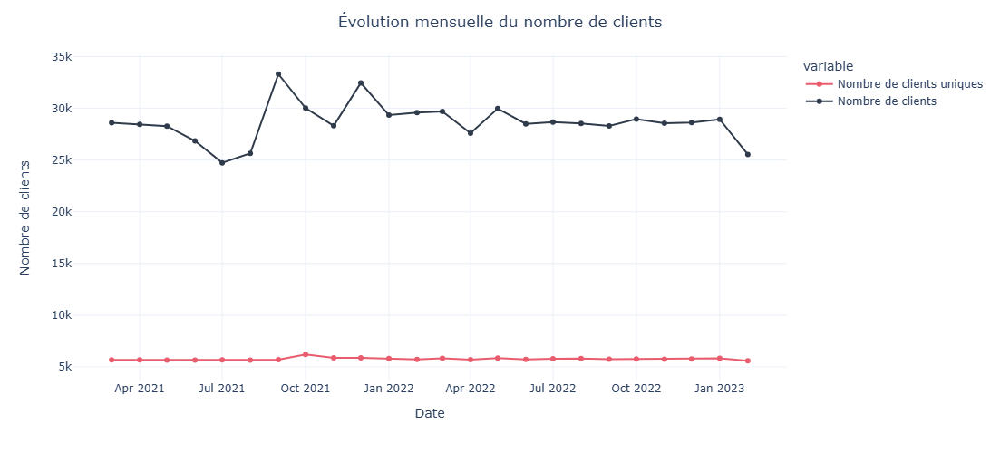

In [32]:
figure3=px.line(
    df_clients,
    x='date',
    y=['Nombre de clients uniques','Nombre de clients'],
    color_discrete_sequence=palette,
    markers=True,
    labels={
        'date': 'Date',
        'value': 'Nombre de clients',
    }
)

figure3.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Évolution mensuelle du nombre de clients',
        'x': 0.5,          
        'xanchor': 'center'}
)

figure3.update_traces(
    hovertemplate='%{y:.0f} clients'
)

figure3.show()

## <u> 3. Les transactions </U>

In [33]:
#  Nombre de produits vendus
moy_nb_dt_vendus=(df_lapage.groupby(pd.Grouper(key='date', freq='MS'))['id_prod'].count().reset_index(name='Nombre de produits vendus'))
moy_nb_dt_vendus.mean()

date                         2022-02-14 20:00:00
Nombre de produits vendus               28647.25
dtype: object

#### Nombre de transactions + évolution dans le temps

In [35]:
# Affichage du nombre de transactions totales sur la période du dataset
print(f"Sur l'intégralité de la période de référence du dataset, il y a eu un total de {df_lapage['session_id'].count()} transactions.")

Sur l'intégralité de la période de référence du dataset, il y a eu un total de 687534 transactions.


In [36]:
#Affichage du nombre de transactions par semaine

# Création d'un dataframe servant de base quotidienne
df_quotidien = df_lapage.groupby(pd.Grouper(key='date', freq='MS'))['session_id'].count().reset_index(name='Transactions_mois')

C:\Users\frnar\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



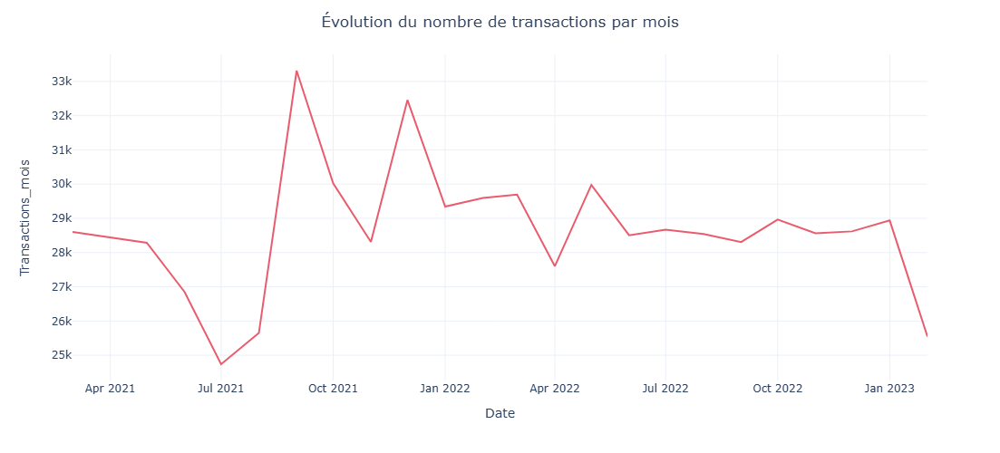

In [37]:
figure5=px.line(
    df_quotidien,
    x='date',
    y='Transactions_mois',    
    color_discrete_sequence=palette,
    markers=False,
    labels={
        'date': 'Date',
        'value': 'Nombre de transactions',
        'variable': 'Tendance'
    }
)

figure5.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Évolution du nombre de transactions par mois',
        'x': 0.5,          
        'xanchor': 'center'}
)

figure5.update_traces(
    hovertemplate='%{y:.0f}'
)

figure5.show()

## <u> 4. Les produits </U>

#### Nombre de produits vendus + évolution dans le temps

In [38]:
# tous les produits sur toute la période, puis par jour, mois, par semaine, par trimestre
#Affichage du nombre de produits vendus par jour
df_prod_uniques = (df_lapage.groupby(pd.Grouper(key='date', freq='MS'))['id_prod'].nunique().reset_index(name='Nombre_Prod_uniques'))
df_prod_uniques

,date,Nombre_Prod_uniques
0,2021-03-01,2482
1,2021-04-01,2492
2,2021-05-01,2471
3,2021-06-01,2414
4,2021-07-01,2369
5,2021-08-01,2404
6,2021-09-01,2560
7,2021-10-01,2506
8,2021-11-01,2432
9,2021-12-01,2505


In [39]:
# tous les produits sur toute la période, puis par jour, mois, par semaine, par trimestre
#Affichage du nombre de produits vendus par jour
df_prod = (df_lapage.groupby(pd.Grouper(key='date', freq='MS'))['id_prod'].count().reset_index(name='Nombre_Prod'))
df_prod

,date,Nombre_Prod
0,2021-03-01,28601
1,2021-04-01,28443
2,2021-05-01,28285
3,2021-06-01,26850
4,2021-07-01,24738
5,2021-08-01,25650
6,2021-09-01,33314
7,2021-10-01,30022
8,2021-11-01,28311
9,2021-12-01,32457


In [40]:
df_prod = df_prod.merge(
    df_prod_uniques,
    on='date',
    how='left'
)
df_prod

,date,Nombre_Prod,Nombre_Prod_uniques
0,2021-03-01,28601,2482
1,2021-04-01,28443,2492
2,2021-05-01,28285,2471
3,2021-06-01,26850,2414
4,2021-07-01,24738,2369
5,2021-08-01,25650,2404
6,2021-09-01,33314,2560
7,2021-10-01,30022,2506
8,2021-11-01,28311,2432
9,2021-12-01,32457,2505


C:\Users\frnar\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



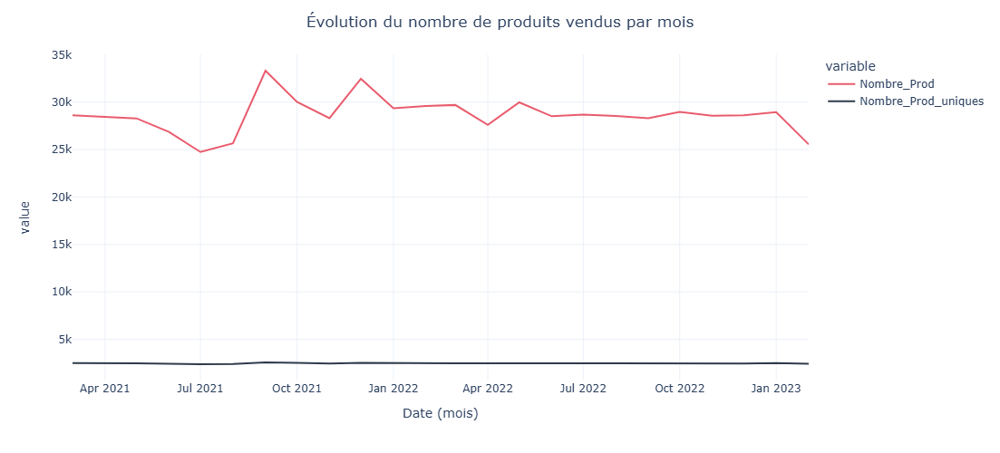

In [41]:
figure6=px.line(
    df_prod,
    x='date',
    y=['Nombre_Prod', 'Nombre_Prod_uniques'],    
    color_discrete_sequence=palette,
    markers=False,
    labels={
        'date': 'Date (mois)'
    }
)

figure6.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=850,
    height=500,
    title={
        'text': 'Évolution du nombre de produits vendus par mois',
        'x': 0.5,          
        'xanchor': 'center'}
)

figure6.update_traces(
    hovertemplate='%{y:.0f}'
    )

figure6.show()

### <u> Top, Flop, la répartition par catégorie</u>

### <u> ***Le Top 10 des produits*** </u> 

In [42]:
# Top 10 global toutes catégories confondues en terme de nombre de ventes
top10_data = df_lapage['id_prod'].value_counts().head(10).reset_index()
top10_data.columns = ['id_prod', 'nombre_de_ventes']
top10_data

,id_prod,nombre_de_ventes
0,1_369,2340
1,1_417,2269
2,1_414,2246
3,1_498,2202
4,1_425,2163
5,1_403,2040
6,1_413,2036
7,1_412,2014
8,1_406,2003
9,1_407,2001


In [43]:
# Top 10 - chaque ligne comprend un 1 produit / une date / un id de session / un client (et ses infos) / un prix / la catégorie 
top_par_categ = df_lapage.groupby(['categ', 'id_prod']).size().reset_index(name='ventes')
top10_par_categ = top_par_categ.sort_values(['categ', 'ventes'], ascending=[True, False]).groupby('categ').head(10)
top_par_categ

,categ,id_prod,ventes
0,0.0,0_0,1242
1,0.0,0_1,487
2,0.0,0_10,22
3,0.0,0_100,3
4,0.0,0_1000,432
...,...,...,...
3260,2.0,2_95,4
3261,2.0,2_96,598
3262,2.0,2_97,13
3263,2.0,2_98,1


In [44]:
df_lapage.groupby(['categ', 'id_prod'], as_index=False)['price'].sum()

,categ,id_prod,price
0,0.0,0_0,4657.50
1,0.0,0_1,5352.13
2,0.0,0_10,394.90
3,0.0,0_100,61.80
4,0.0,0_1000,2954.88
...,...,...,...
3260,2.0,2_95,395.96
3261,2.0,2_96,28650.18
3262,2.0,2_97,2092.87
3263,2.0,2_98,149.74


In [45]:
# Nombre de ventes par produit et par catégorie + top 10
top_par_categ = df_lapage.groupby(['categ', 'id_prod']).size().reset_index(name='ventes')
top10_par_categ = top_par_categ.sort_values(['categ', 'ventes'], ascending=[True, False]).groupby('categ').head(10)

In [46]:
# top10_par_categ['categ'] = top10_par_categ['categ'].astype(str)

C:\Users\frnar\anaconda3\Lib\site-packages\plotly\express\_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



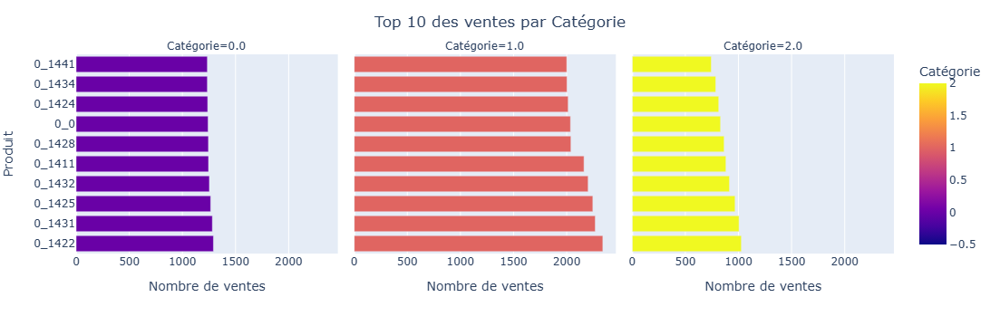

In [47]:
fig2 = px.bar(
        top10_par_categ, 
        x='ventes', 
        y='id_prod', 
        color='categ', 
        color_discrete_map=palette,
        facet_col='categ',
        facet_col_wrap=3,  
        orientation='h',
        labels={'id_prod': 'Produit', 'ventes': 'Nombre de ventes','categ': 'Catégorie'}
)

fig2.update_layout(title_text='Top 10 des ventes par Catégorie', 
                title_x=0.5, 
                xaxis={'categoryorder':'array', 'categoryarray': top10_par_categ['ventes']},
                yaxis_tickformat=',.2f')
fig2.update_yaxes(matches=None)

fig2.show()

In [48]:
# CA par produit top 10
top10_ca=df_b2c.groupby(['id_prod','categ'], as_index=False)['price'].sum().sort_values('price', ascending=False).head(10)

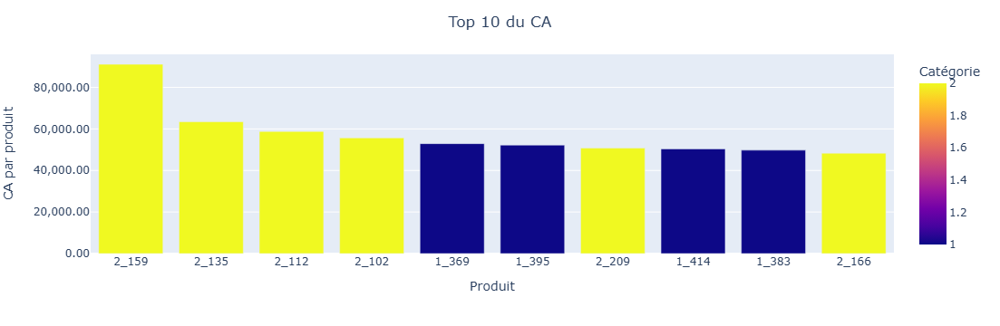

In [49]:
figtop10ca= px.bar(
        top10_ca, 
        y='price', 
        x='id_prod', 
        color='categ', 
        color_discrete_map=palette,
        labels={'id_prod': 'Produit', 'price': 'CA par produit', 'categ': 'Catégorie'},     
        hover_data={'price': ':.2f'})

figtop10ca.update_layout(title_text='Top 10 du CA', 
                        title_x=0.5, 
                        xaxis={'categoryorder':'array', 'categoryarray': top10_ca['id_prod']},
                        yaxis_tickformat=',.2f')
figtop10ca.update_yaxes(matches=None)

figtop10ca.update_traces(hovertemplate='%{y:.0f} €')

figtop10ca.show()

### <u> ***Le Flop 10*** </u> 

In [50]:
# Nombre de ventes par produit et par catégorie + flop 10
flop_par_categ = df_lapage.groupby(['categ', 'id_prod']).size().reset_index(name='ventes')
flop10_par_categ = flop_par_categ.sort_values(['categ', 'ventes'], ascending=[True, True]).groupby('categ').head(10)

In [51]:
# Nombre d'exemplaires vendus par par catégorie
ventes_par_prod = (
    df_lapage
    .groupby(['categ', 'id_prod'])
    .size()
    .reset_index(name='ventes')
)

# Moyenne d'exemplaires vendus par catégorie
moyenne_par_categ = ventes_par_prod.groupby('categ')['ventes'].mean()

moyenne_par_categ


categ
0.0    181.264834
1.0    319.663501
2.0    154.588983
Name: ventes, dtype: float64

C:\Users\frnar\anaconda3\Lib\site-packages\plotly\express\_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



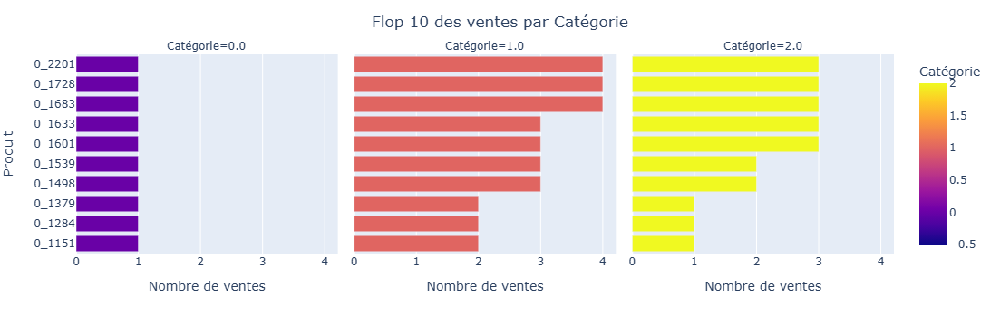

In [52]:
fig3 = px.bar(flop10_par_categ, 
        x='ventes', 
        y='id_prod', 
        color='categ', 
        color_discrete_map=palette,
        facet_col='categ',
        facet_col_wrap=3,  
        orientation='h',
        labels={'id_prod': 'Produit', 'ventes': 'Nombre de ventes','categ': 'Catégorie'})

fig3.update_layout(title_text='Flop 10 des ventes par Catégorie', 
                title_x=0.5,
                xaxis={'categoryorder':'array', 'categoryarray': flop10_par_categ['ventes']},
                yaxis_tickformat=',.2f')
fig3.update_yaxes(matches=None)
fig3.show()

In [53]:
# Nombre de références vendues une seule fois
counts = df_lapage['id_prod'].value_counts()
produits_uniques = counts[counts == 1].reset_index()

print(f"Le nombre de livres vendus une seule fois : {len(produits_uniques)} références")

Le nombre de livres vendus une seule fois : 18 références


In [54]:
# Liste des "flops" avec la catégorie
flops = produits_uniques.merge(df_lapage[['id_prod', 'categ']].drop_duplicates(), on='id_prod', how='left')

categ_flops = flops['categ'].value_counts().reset_index()
categ_flops

,categ,count
0,0.0,15
1,2.0,3


Nous observons que 18 produits n'ont été vendus qu'une seule fois sur la période. La majorité de ces références appartiennent à la catégorie 0, ce qui pourrait indiquer un besoin de renouvellement du catalogue sur ce segment.

In [55]:
# CA par produit et par catégorie + top 10
flop10_ca=df_lapage.groupby(['categ', 'id_prod'], as_index=False)['price'].sum().sort_values('price', ascending=True).head(10)
flop10_ca

,categ,id_prod,price
595,0.0,0_1539,0.99
313,0.0,0_1284,1.38
719,0.0,0_1653,1.98
1784,0.0,0_541,1.99
665,0.0,0_1601,1.99
2079,0.0,0_807,1.99
802,0.0,0_1728,2.27
549,0.0,0_1498,2.48
2179,0.0,0_898,2.54
925,0.0,0_1840,2.56


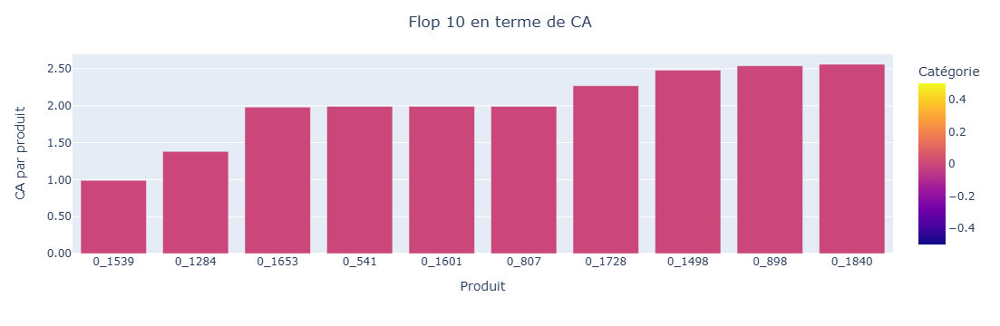

In [56]:
figflop10ca= px.bar(
        flop10_ca, 
        y='price', 
        x='id_prod', 
        color='categ', 
        color_discrete_map=palette,
        labels={'id_prod': 'Produit', 'price': 'CA par produit','categ': 'Catégorie'},
        hover_data={'price': ':.2f'})

figflop10ca.update_layout(title_text='Flop 10 en terme de CA', 
                        title_x=0.5,
                        xaxis={'categoryorder':'array', 'categoryarray': flop10_ca['id_prod']},
                        yaxis_tickformat=',.2f')
figflop10ca.update_yaxes(matches=None)
figflop10ca.update_traces(hovertemplate='%{y:.2f} €')
figflop10ca.show()

## <u> 5. Le profil de nos clients </U>

### <u> SEGMENTATION DES CLIENTS : BtoB ET BtoC </u>

#### REPARTITION DES PRODUITS VENDUS EN B2B

In [57]:
# répartition des clients b2b par catégorie
client_categorie_b2b=df_b2b.groupby('categ')['id_prod'].nunique().reset_index()
client_categorie_b2b.columns = ['categ', 'nombre_produits_uniques']

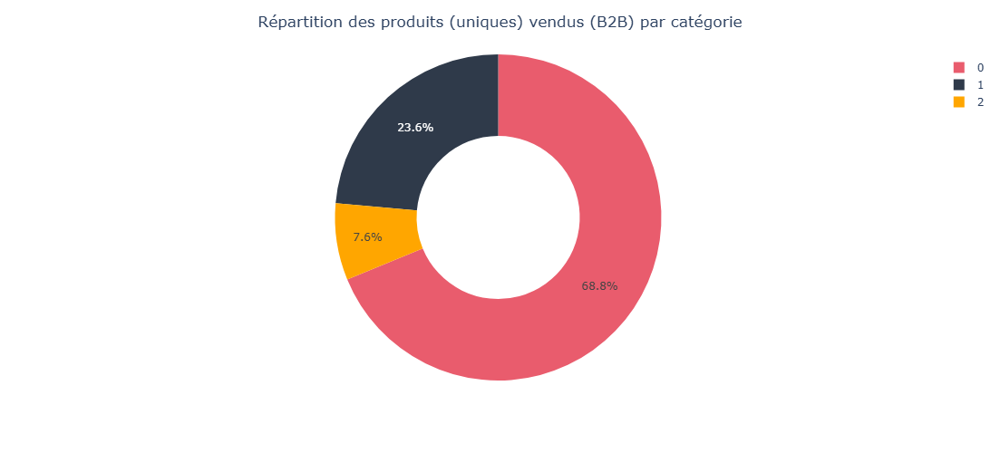

In [58]:
# palette = list(palette.values())

fig_clients_b2b = px.pie(
    client_categorie_b2b, 
    values='nombre_produits_uniques', 
    names='categ',
    hole=0.5,
    color_discrete_sequence=palette
)
fig_clients_b2b.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Répartition des produits (uniques) vendus (B2B) par catégorie',
        'x': 0.5,          
        'xanchor': 'center'}
)

fig_clients_b2b.show()

In [59]:
client_categorie_b2b_total=df_b2b.groupby('categ')['id_prod'].value_counts().reset_index(name='nombre_produits')
client_categorie_b2b_total

,categ,id_prod,nombre_produits
0,0.0,0_1438,117
1,0.0,0_1360,101
2,0.0,0_1411,101
3,0.0,0_1378,100
4,0.0,0_0,95
...,...,...,...
2350,2.0,2_57,1
2351,2.0,2_64,1
2352,2.0,2_66,1
2353,2.0,2_88,1


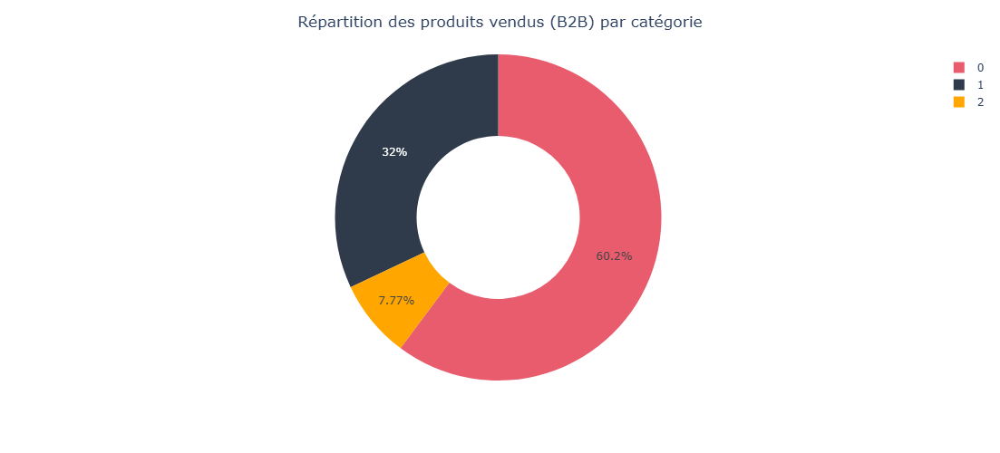

In [60]:
fig_clients_b2b_total = px.pie(
    client_categorie_b2b_total, 
    values='nombre_produits',
    names='categ', 
    hole=0.5,
    color_discrete_sequence=palette
)
fig_clients_b2b_total.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Répartition des produits vendus (B2B) par catégorie',
        'x': 0.5,          
        'xanchor': 'center'}
)

fig_clients_b2b_total.show()

In [57]:
figureb2b = px.histogram(
    df_b2b,
    x="client_id",
    color="categ",
    barmode="group",
    nbins=20,
    color_discrete_sequence=palette
)
figureb2b.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Histogramme représentant le nombre d\'achats par clients B to B, par catégories',
        'x': 0.5,          
        'xanchor': 'center'}
)
figureb2b.update_traces(hovertemplate='%{y:.0f}')

figureb2b.show()

In [61]:
# var_a = df_b2b.groupby(['client_id','categ'])['price'].sum().reset_index()
# df_b2b

C:\Users\frnar\anaconda3\Lib\site-packages\plotly\express\_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



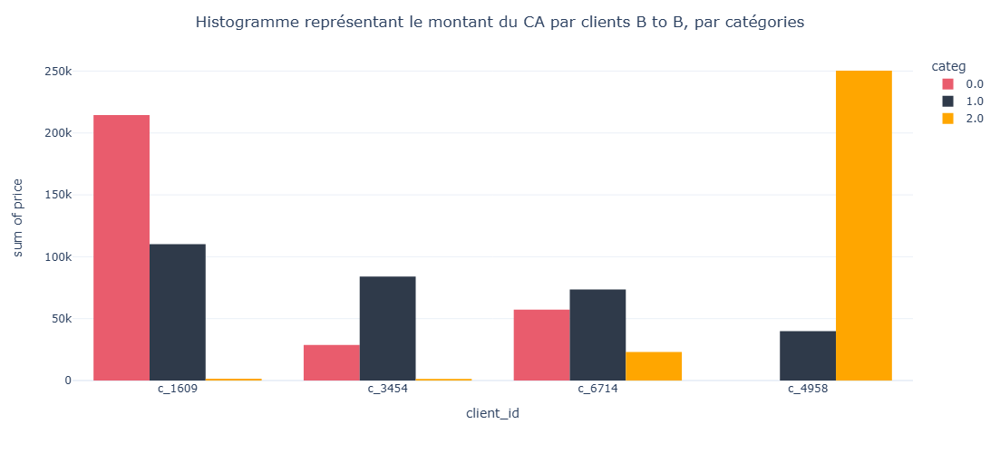

In [62]:
# Histogramme représentant le montant du CA par clients B to B, par catégories
figureb2b_ca = px.histogram(
    df_b2b,
    x="client_id",
    y="price",    
    color="categ",
    barmode="group",
    nbins=20,
    color_discrete_sequence=palette
)
figureb2b_ca.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Histogramme représentant le montant du CA par clients B to B, par catégories',
        'x': 0.5,          
        'xanchor': 'center'}
)
figureb2b_ca.update_traces(hovertemplate='%{y:.0f} €')

figureb2b_ca.show()

In [63]:
#  Evolution du CA pour les B2B
df_2b2_mensuel=df_b2b.groupby([pd.Grouper(key='date', freq='MS'),'client_id'])['price'].sum().to_frame().reset_index()
df_2b2_mensuel

,date,client_id,price
0,2021-03-01,c_1609,13740.67
1,2021-03-01,c_3454,4513.55
2,2021-03-01,c_4958,12073.43
3,2021-03-01,c_6714,6194.25
4,2021-04-01,c_1609,13543.34
...,...,...,...
91,2023-01-01,c_6714,7437.54
92,2023-02-01,c_1609,12110.45
93,2023-02-01,c_3454,4637.20
94,2023-02-01,c_4958,11908.58


C:\Users\frnar\anaconda3\Lib\site-packages\plotly\express\_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

C:\Users\frnar\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



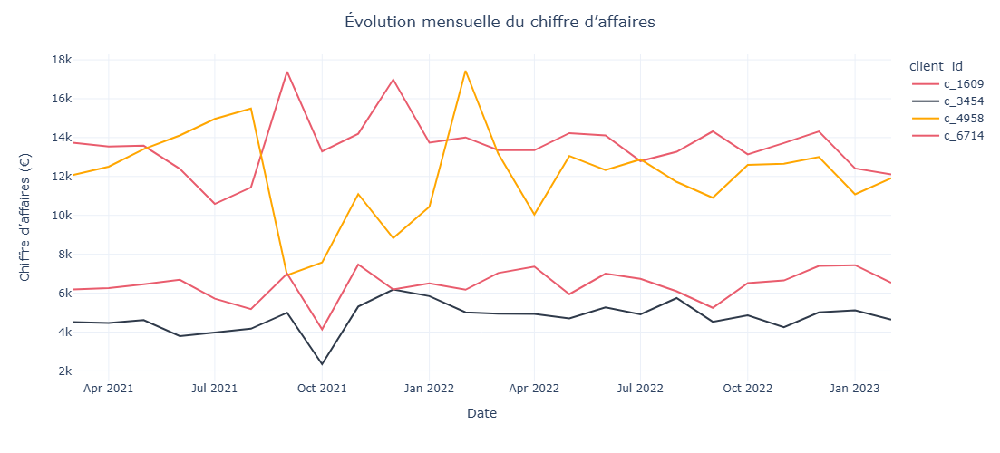

In [64]:
# Évolution mensuelle du chiffre d’affaires
figureb2bca = px.line(
    df_2b2_mensuel, 
    x='date', 
    y='price', 
    color='client_id',
    color_discrete_sequence=palette,
    markers=False,
    
    labels={
        'date': 'Date',
        'price': 'Chiffre d’affaires (€)',
        'categ':'Client'
    }
)

figureb2bca.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=850,
    height=500,
    title={
        'text': 'Évolution mensuelle du chiffre d’affaires',
        'x': 0.5,          
        'xanchor': 'center'},
)

figureb2bca.update_traces(
    hovertemplate='%{y:.0f} €'
    )

figureb2bca.show()

#### REPARTITION DES PRODUITS VENDUS EN B2C

In [65]:
# répartition des clients b2c par catégorie
client_categorie_b2c=df_b2c.groupby('categ')['id_prod'].nunique().reset_index()
client_categorie_b2c.columns = ['categ', 'nombre_produits_uniques']

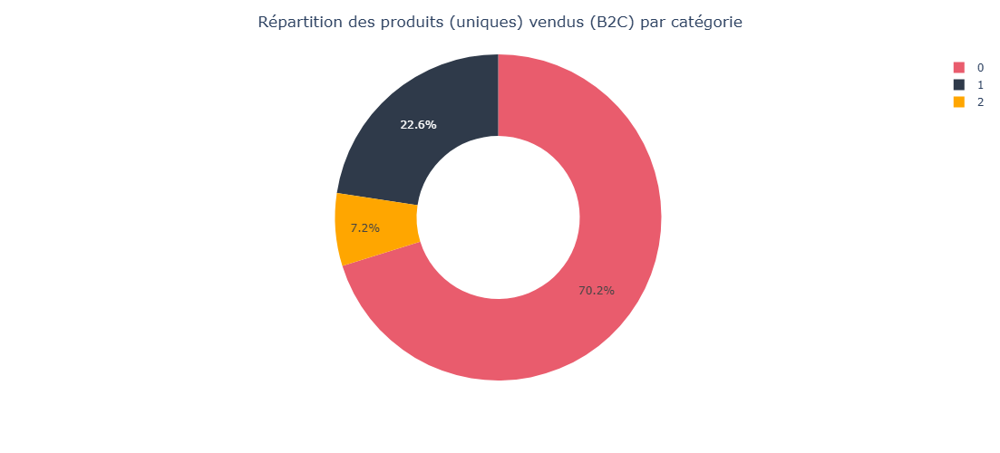

In [66]:
# répartition des produits (uniques) vendus (B2C) par catégorie

fig_clients_b2c = px.pie(
    client_categorie_b2c, 
    names='categ',
    values='nombre_produits_uniques',
    hole=0.5,
    color_discrete_sequence=palette
)
fig_clients_b2c.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Répartition des produits (uniques) vendus (B2C) par catégorie',
        'x': 0.5,          
        'xanchor': 'center'}
)

fig_clients_b2c.show()

In [68]:
# Répartition de produits vendus
client_categorie_b2c_total=df_b2c.groupby('categ')['id_prod'].value_counts().reset_index(name='nombre_produits')

In [69]:
# Répartition des produits vendus (B2C) par catégorie
fig_clients_b2c = px.pie(
    client_categorie_b2c_total, 
    names='categ',
    values='nombre_produits',   
    hole=0.5,
    color_discrete_sequence=palette
)

fig_clients_b2c.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=750,
    height=500,
    title={
        'text': 'Répartition des produits vendus (B2C) par catégorie',
        'x': 0.5,          
        'xanchor': 'center'}
)
fig_clients_b2c.show()

### <u> Utilisation du df_b2c pour identifier le profil des clients </u> 

In [67]:
# classement de l'Age des clients par catégorie
df_b2c.sort_values(by=['categ', 'birth'], ascending=[True, True]).reset_index(drop=True)

,id_prod,date,session_id,client_id,price,categ,sex,birth,type_client
0,0_1563,2021-03-25,s_11322,c_8362,3.99,0,f,1929,B to C
1,0_1159,2021-04-07,s_17164,c_577,7.99,0,m,1929,B to C
2,0_1729,2021-04-15,s_20794,c_577,14.99,0,m,1929,B to C
3,0_655,2021-04-15,s_20794,c_577,9.99,0,m,1929,B to C
4,0_1626,2021-05-02,s_28633,c_577,14.02,0,m,1929,B to C
...,...,...,...,...,...,...,...,...,...
640729,2_39,2023-02-28,s_348194,c_7483,57.99,2,m,2004,B to C
640730,2_208,2023-02-28,s_348339,c_6464,54.87,2,m,2004,B to C
640731,2_155,2023-02-28,s_348357,c_1852,46.99,2,m,2004,B to C
640732,2_163,2023-02-28,s_348364,c_3009,68.99,2,m,2004,B to C


In [68]:
df_b2c.info()
df_b2c.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 640734 entries, 0 to 687533
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   id_prod      640734 non-null  object        
 1   date         640734 non-null  datetime64[ns]
 2   session_id   640734 non-null  object        
 3   client_id    640734 non-null  object        
 4   price        640734 non-null  float64       
 5   categ        640734 non-null  int64         
 6   sex          640734 non-null  object        
 7   birth        640734 non-null  int64         
 8   type_client  640734 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 48.9+ MB


,date,price,categ,birth
count,640734,640734.000000,640734.000000,640734.000000
mean,2022-03-01 07:53:09.800448,17.391565,0.446833,1977.792024
min,2021-03-01 00:00:00,0.620000,0.000000,1929.000000
25%,2021-09-10 00:00:00,8.990000,0.000000,1971.000000
50%,2022-02-27 00:00:00,13.990000,0.000000,1979.000000
75%,2022-08-28 00:00:00,19.040000,1.000000,1987.000000
max,2023-02-28 00:00:00,300.000000,2.000000,2004.000000
std,NaN,18.003423,0.591360,13.879682


In [69]:
# Création de la colonne age, correspondant à la différence entre la date du jour et l'année de 'birth' 
# Pour que la bonne catégorie d'âge soit retenue, il faut prendre la date d'achat comme date de référence

df_b2c['date'] = pd.to_datetime(df_b2c['date'])
df_b2c['birth'] = pd.to_datetime(df_b2c['birth'], format='%Y')
df_b2c['age'] = (df_b2c['date'] - df_b2c['birth']).dt.days // 365

In [ ]:
# Histogramme empilé du CA par âges et catégories
figureageca = px.histogram(
    df_b2c,
    x="age",
    color="categ",
    barmode="group",
    nbins=20,
    color_discrete_sequence=palette
)
figureageca.update_layout(
    template='plotly_white',
    hovermode='x unified',
    width=850,
    height=500,
    title={
        'text': 'Histogramme empilé du CA par âges et catégories',
        'x': 0.5,          
        'xanchor': 'center'}
)

figureageca.update_traces(hovertemplate='%{y:.0f} €')

figureageca.show()


In [72]:
#  Répartition des clients par genre
genre=df_b2c.groupby('sex')['client_id'].nunique().reset_index(name='nombre_produits_uniques')
genre

,sex,nombre_produits_uniques
0,f,4478
1,m,4118


In [ ]:
# Etablissement du top 10 des clients (ca)
top10_ca=df_b2c.groupby('client_id')['price'].sum().reset_index(name='CA_total')
top10_ca.columns = ['client_id', 'CA_total']
top10_ca=top10_ca.sort_values(by='CA_total',ascending=False).head(10)

In [ ]:
# Graphique du Top 10 des clients en terme de CA généré
fig_top10_ca = px.histogram(
    top10_ca, 
    x= 'client_id', 
    y='CA_total',
    labels={'client_id': 'Identifiant Client', 'CA_total': 'Chiffre d\'Affaires Total (€)'},
    color='client_id',
    color_discrete_sequence=palette
)
fig_top10_ca.update_layout(
    showlegend=False,      
    template='plotly_white',
    hovermode='x unified',
    width=950,
    height=500,
    title={
        'text': 'Top 10 des clients B2C par Chiffre d\'Affaires',
        'x': 0.5,          
        'xanchor': 'center'}
)

fig_top10_ca.update_traces(hovertemplate='%{y:.0f} €')

fig_top10_ca.show()


In [ ]:
# Flop 10 des clients en terme de CA généré
flop10_ca=df_b2c.groupby('client_id')['price'].sum().reset_index(name='CA_total')
flop10_ca.columns = ['client_id', 'CA_total']
flop10_ca=flop10_ca.sort_values(by='CA_total',ascending=True).head(10)

In [76]:
# Graphique du Flop 10 des clients en terme de CA généré
fig_flop10_ca = px.bar(
    flop10_ca, 
    x= 'client_id', 
    y='CA_total',
    labels={'client_id': 'Identifiant Client', 'CA_total': 'Chiffre d\'Affaires Total (€)'},
    color='client_id',
    color_discrete_sequence=palette
)
fig_flop10_ca.update_layout(
    showlegend=False,      
    template='plotly_white',
    hovermode='x unified',
    width=950,
    height=500,
    title={
        'text': 'Flop 10 des clients B2C par Chiffre d\'Affaires',
        'x': 0.5,          
        'xanchor': 'center'}
)
fig_top10_ca.update_traces(hovertemplate='%{y:.0f} €')
fig_flop10_ca.show()


### Analyse des clients par âge

In [77]:
# NOMBRE DE CLIENTS GROUPES PAR AGE 
clients_par_age = df_b2c.groupby('age')['client_id'].nunique().reset_index()
clients_par_age = clients_par_age.rename(columns={'client_id': 'nombre_clients'})
print(clients_par_age)

    age  nombre_clients
0    17             435
1    18             573
2    19             614
3    20             372
4    21             361
..  ...             ...
73   90              16
74   91              13
75   92              11
76   93               6
77   94               3

[78 rows x 2 columns]


In [78]:
figure_age=px.bar(
    df_b2c,
    x='age',
    y='client_id',
    title='Répartition des ventes par âge', 
    color_discrete_sequence=palette
    )
figure_age.show()

Analyse des clients par âge et catégories achetées

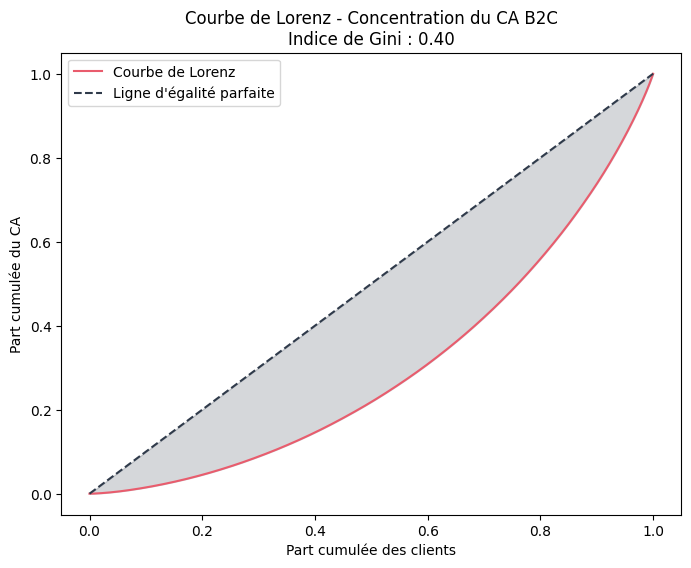

In [79]:
ca_b2c = df_b2c.groupby('client_id')['price'].sum().values
n = len(ca_b2c)

# 2. Trier les CA par ordre croissant (obligatoire pour Lorenz)
lorenz = np.sort(ca_b2c)

# 3. Calculer la somme cumulée des CA (ordonnées) et la part de population (abscisses)
lorenz_cum = np.cumsum(lorenz) / lorenz.sum()
lorenz_cum = np.append([0], lorenz_cum) # On commence à 0

# Part cumulée de la population (de 0 à 1)
xaxis = np.linspace(0-1/n, 1, len(lorenz_cum)) 

# 4. Calcul de l'indice de Gini
# Aire sous la courbe de Lorenz
AUC = (lorenz_cum.sum() - lorenz_cum[-1]/2 - lorenz_cum[0]/2) / n
# Aire entre la diagonale et la courbe
S = 0.5 - AUC
gini = 2 * S

# 5. Graphique
plt.figure(figsize=(8,6))

plt.plot(xaxis, lorenz_cum, color="#e95c6d", label='Courbe de Lorenz') 
plt.plot([0,1], [0,1],color="#2f3a4a", linestyle='--', label='Ligne d\'égalité parfaite')
plt.fill_between(xaxis, xaxis, lorenz_cum, color="#2f3a4a", alpha=0.2)
plt.title(f'Courbe de Lorenz - Concentration du CA B2C\nIndice de Gini : {gini:.2f}')
plt.xlabel('Part cumulée des clients')
plt.ylabel('Part cumulée du CA')
plt.legend()
plt.grid(False)
plt.show()

Un Gini de 0.40, c'est l'indice classique d'une activité commerciale saine mais contrastée.

Cela suit souvent la Loi de Pareto : environ 20% des clients font 50% à 60% du CA.

Analyse : Tu as beaucoup de "petits" clients qui achètent un livre de temps en temps, et une base de clients fidèles ("gros lecteurs") qui achètent très régulièrement. C'est ce qui "creuse" la courbe.

Clientèle hétérogène : présence de "gros lecteurs" fidèles.

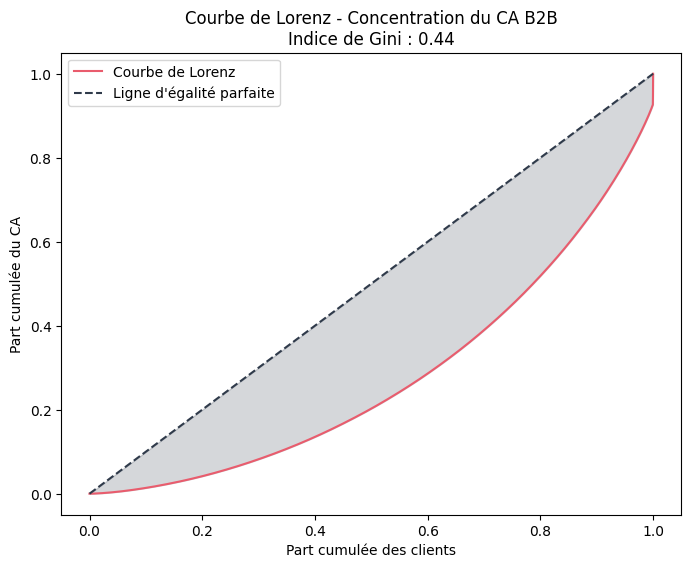

In [ ]:
ca_clients = df_lapage.groupby('client_id')['price'].sum().values
n = len(ca_clients)

# Trier les CA par ordre croissant (obligatoire pour Lorenz)
lorenz = np.sort(ca_clients)

# calcul de la somme cumulée des CA (ordonnées) et la part de population (abscisses)
lorenz_cum = np.cumsum(lorenz) / lorenz.sum()
lorenz_cum = np.append([0], lorenz_cum) 

# Part cumulée de la population (de 0 à 1)
xaxis = np.linspace(0-1/n, 1, len(lorenz_cum)) 

#Calcul de l'indice de Gini
AUC = (lorenz_cum.sum() - lorenz_cum[-1]/2 - lorenz_cum[0]/2) / n

S = 0.5 - AUC
gini = 2 * S

In [ ]:
# Graphique
plt.figure(figsize=(8,6))

plt.plot(xaxis, lorenz_cum, color="#e95c6d", label='Courbe de Lorenz') 
plt.plot([0,1], [0,1],color="#2f3a4a", linestyle='--', label='Ligne d\'égalité parfaite')
plt.fill_between(xaxis, xaxis, lorenz_cum, color="#2f3a4a", alpha=0.2)
plt.title(f'Courbe de Lorenz - Concentration du CA B2B\nIndice de Gini : {gini:.2f}')
plt.xlabel('Part cumulée des clients')
plt.ylabel('Part cumulée du CA')
plt.legend()
plt.grid(False)
plt.show()

Le fait que l'indice grimpe à 0.44 quand on mélange tous les clients est logique : l'écart entre le plus petit client B2C (qui achète un livre à 5€) et le plus gros client B2B (qui achète pour 250 000€) est énorme.
Forte concentration due à la présence des 4 clients "Outliers".

In [81]:
df_b2c.to_csv(r'..\..\projet9_Lapage\data\processed\df_b2c.csv',sep=';', encoding='utf-8', index=False)